## Reporting variability honestly

Report every seed, mean, standard deviation, range, and the baseline. With only a few seeds, do not imply a precisely estimated probability distribution. For data sufficiency, show error versus number and location of development Reynolds cases; count alone can hide poor coverage.

To evaluate an uncertainty indicator, compare spread and actual error across complete blind cases. Ranking agreement is a useful first check, but calibration requires coverage analysis at declared intervals or thresholds.


## Worked check: finite-ensemble spread
For predictions [0,1,2,3,4], mean=2, sum of squared deviations=10.
The sample variance is 10/(5−1)=2.5 and sample standard deviation is √2.5≈1.5811.
The population-of-these-five standard deviation would be √2≈1.4142.
This notebook uses `ddof=1`, matching the guide. Neither quantity alone is a
calibrated predictive interval; shared CFD/model bias can be absent from both.

## Assessment contract: public held-out cases are not a new blind experiment
The course has already displayed Re=175, 275 and 375 in earlier lessons, and
some other project test cases have appeared as development/benchmark cases.
Keeping a case out of fitting is necessary, but does not make it unseen to a
student who has inspected it before. Here **public held-out regression test**
is the correct label for reused cases, including older tables labelled "blind".
Those historical labels describe the original author protocol, not a new claim
of student blindness. Do not revise settings using these results and call the
same assessment untouched.

Before final assessment, record a dated manifest containing development cases,
validation case, all candidates/seeds, thresholds, source/data hashes, and an
exposure log (case, earlier lesson, whether viewed). If an instructor provides
new cases, their fields remain withheld until that manifest is frozen. Otherwise
report a reproducible public-case study, **not a new blind generalization study**.
No synthetic replacement test or new CFD qualification is implied by this revision.

# Project Track 4 - Uncertainty and Data-Sufficiency Study

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week05_06/P4_Uncertainty_Study.ipynb)

**Choose one variant:**

- **4A Training-seed uncertainty:** repeat the same DNN training and build an ensemble uncertainty map.
- **4B Training-case sufficiency:** hold architecture fixed and vary only the number of Reynolds-number cases.

The goal is to distinguish one lucky training run from a reproducible scientific result.

## Files

Everything this notebook needs is in the repository: the shared helpers `common/w4utils.py` and `common/w5_common.py`, and the fixed reference dataset `data/cavity_data.npz`. The bootstrap cell locates them from a checkout or a Colab clone; no manual upload is required.

<!-- MIE690A enriched learner edition v2 -->

## How to learn from this notebook

This is a guided computational laboratory, not a script to execute without reading. For every numbered stage:

1. read the physical question and write a prediction;
2. inspect the inputs, outputs, units, and split before running code;
3. run the cell and check assertions/warnings;
4. compare with the stated baseline or physical diagnostic; and
5. write one or two sentences explaining what the result does **and does not** establish.

Use **Restart and Run All** before treating any output as final. Hidden state from out-of-order execution is a reproducibility failure.

### Evidence contract

Keep four kinds of evidence separate:

- **numerical evidence:** residuals, accepted cases, data hashes, grid/time/particle budgets;
- **statistical evidence:** losses, relative errors, variability across seeds/cases;
- **physical evidence:** centerlines, walls, divergence, vortex structure, positivity, moments;
- **computational evidence:** runtime, memory, saved configuration, and machine-readable metrics.

A claim is only as strong as the weakest relevant layer.


## Learning objectives: uncertainty is not one number

This track studies two different sources of variability. Variant 4A changes training initialization while holding data fixed. Variant 4B changes the amount of development information while holding the test and training protocol fixed. You should be able to report distributions rather than a preferred run and test whether a proposed uncertainty indicator tracks actual blind error.

Prerequisites: random seeds, case-wise splits, ensemble mean/spread, validation-only model selection, and confidence versus calibration.


In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week05_06"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

# Repository/Colab bootstrap. Run this before the import cell below.
from pathlib import Path
import sys

def _find_course_root(start=Path.cwd()):
    candidates = [start, *start.parents]
    for base in candidates:
        if (base / "common" / "w5_common.py").exists():
            return base
    # Fallback: helper files placed beside the notebook.
    if (start / "w5_common.py").exists():
        return start
    raise FileNotFoundError(
        "Course root not found. Run this notebook from a FlowMLLab checkout "
        "(the Colab bootstrap cell clones one automatically)."
    )

COURSE_ROOT = _find_course_root()
COMMON_DIR = COURSE_ROOT / "common" if (COURSE_ROOT / "common").exists() else COURSE_ROOT
DATASET_PATH = COURSE_ROOT / "data" / "cavity_data.npz"
if not DATASET_PATH.exists():
    DATASET_PATH = COURSE_ROOT / "cavity_data.npz"
sys.path.insert(0, str(COMMON_DIR))
print("Course root:", COURSE_ROOT)
print("Common helpers:", COMMON_DIR)
print("Dataset:", DATASET_PATH)


Course root: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-early-cpu-qa-20261121/final_project_followup/repo
Common helpers: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-early-cpu-qa-20261121/final_project_followup/repo/common
Dataset: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-early-cpu-qa-20261121/final_project_followup/repo/data/cavity_data.npz


In [2]:
import time,importlib
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import w4utils,w5_common
importlib.reload(w4utils);importlib.reload(w5_common)
assert w4utils.W4_UTILS_VERSION == "6.3", "common/w4utils.py is not the expected version 6.3; use a current checkout."
assert w5_common.W5_COMMON_VERSION == "1.2", "common/w5_common.py is not the expected version 1.2; use a current checkout."
data=w5_common.require_week4_files(str(DATASET_PATH)); VARIANT="4A"
VAL_RE=300; TEST_RE=[175,275,375]; HIDDEN=(64,64,64)


## A practical uncertainty taxonomy

- **Numerical error:** discretization, solver convergence, pressure recovery, or finite sampling window in the labels.
- **Aleatoric/statistical variability:** irreducible sampling variation in stochastic particle data.
- **Epistemic/model variability:** sensitivity to limited data, architecture, initialization, or training.
- **Distribution shift:** blind physical conditions that are not represented by development support.

An ensemble of training seeds probes only a narrow part of epistemic variability. Small ensemble spread does not prove low error; all members can be confidently wrong under extrapolation.


## 4A. Repeated training seeds

Architecture, data, optimizer, and stopping rule remain fixed. Only initialization and stochastic optimization change.

In [3]:
SEEDS=[11,22,33,44,55]
BASE_TRAIN=[100,150,200,225,250,350,400]
seed_rows=[];seed_predictions={}
if VARIANT=="4A":
    for seed in SEEDS:
        t0=time.time()
        b=w5_common.train_pointwise_model(data,BASE_TRAIN,VAL_RE,hidden=HIDDEN,
            stride=2,seed=seed,epochs=850,patience=60)
        fit_seconds=time.time()-t0
        seed_predictions[seed]={}
        for r in TEST_RE:
            pred=w5_common.predict_case(b,r,data["x"],data["y"])
            seed_predictions[seed][r]=pred
            seed_rows.append({"seed":seed,"Re":r,"training_seconds":fit_seconds,
                              **w5_common.evaluate_prediction(data,r,pred)})
    seed_results=pd.DataFrame(seed_rows);display(seed_results)


,seed,Re,training_seconds,relative_L2_uv,MAE_u,MAE_v,p95_vector_error,max_vector_error,div_l2_pred,div_linf_pred,...,wall_max_error,lid_u_mae,centerline_rel_L2_u,centerline_rel_L2_v,centerline_rel_L2_p_vertical,centerline_rel_L2_p_horizontal,relative_L2_p,relative_L2_p_interior,MAE_p,max_p_error
0,11,175,111.780774,0.053429,0.004958,0.002669,0.012168,0.474913,0.286108,10.571700,...,0.471876,0.027051,0.028081,0.017439,0.034545,0.062072,0.063539,0.035818,0.001458,0.119537
1,11,275,111.780774,0.049973,0.004534,0.002704,0.012861,0.446062,0.272488,9.215792,...,0.446026,0.023596,0.023457,0.012444,0.033729,0.029846,0.051022,0.034904,0.001269,0.078049
2,11,375,111.780774,0.052676,0.004653,0.003133,0.012207,0.444660,0.283233,9.489749,...,0.444632,0.026664,0.022594,0.016968,0.028916,0.042900,0.054649,0.037189,0.001300,0.071042
3,22,175,108.555966,0.055978,0.004021,0.002918,0.011557,0.569621,0.384537,13.462252,...,0.568150,0.030575,0.011889,0.019834,0.034108,0.056507,0.079116,0.050170,0.001285,0.188444
4,22,275,108.555966,0.052048,0.003960,0.002755,0.011988,0.598395,0.350890,12.816774,...,0.598066,0.025237,0.011288,0.015841,0.039835,0.043035,0.076085,0.046886,0.001270,0.140224
5,22,375,108.555966,0.052366,0.003972,0.002984,0.011933,0.603334,0.346550,12.574475,...,0.603259,0.023545,0.015514,0.019149,0.026247,0.032911,0.071519,0.041889,0.001240,0.115369
6,33,175,108.149377,0.052110,0.004515,0.002632,0.012969,0.462183,0.335881,11.230890,...,0.460605,0.034309,0.019515,0.015086,0.044561,0.064290,0.059835,0.036543,0.001368,0.144592
7,33,275,108.149377,0.046527,0.003971,0.002623,0.010749,0.397402,0.316493,11.588133,...,0.392558,0.019973,0.014484,0.007652,0.031256,0.028017,0.055729,0.032928,0.001179,0.103978
8,33,375,108.149377,0.052901,0.004528,0.002995,0.011394,0.436113,0.346350,12.192523,...,0.434072,0.020160,0.014804,0.009047,0.029426,0.029732,0.054623,0.037738,0.001235,0.069843
9,44,175,106.569396,0.048218,0.004026,0.002552,0.014105,0.483577,0.276482,9.548003,...,0.483097,0.024034,0.023696,0.011291,0.050047,0.057262,0.061323,0.028194,0.001290,0.131560


## Design the comparison before running it

For a seed study, keep case lists, architecture, epoch budget, scaling rule, and metrics identical. For a data-sufficiency study, use nested development sets so that “more data” really adds cases rather than replacing them. Do not change two factors and attribute the outcome to one.

**Prediction prompt:** Will ensemble spread be largest where the true error is largest? Write a reason it might succeed and a reason it might fail.


## 4B. Number of development cases

The architecture and spatial sampling stay fixed. Only the number and coverage of physical cases change. The labels below count **development cases**, including the fixed validation case at `Re=300`; the result table reports both development-case and actual training-case counts.

In [4]:
DEV_CASE_SETS={
    "4_dev_cases":[100,200,300,400],
    "6_dev_cases":[100,150,200,250,300,400],
    "8_dev_cases":[100,150,200,225,250,300,350,400],
}
size_rows=[];size_predictions={}
if VARIANT=="4B":
    for label,cases in DEV_CASE_SETS.items():
        val=300; train=[r for r in cases if r!=val]
        t0=time.time()
        b=w5_common.train_pointwise_model(data,train,val,hidden=HIDDEN,
            stride=2,seed=690,epochs=850,patience=60)
        fit_seconds=time.time()-t0
        size_predictions[label]={}
        for r in TEST_RE:
            pred=w5_common.predict_case(b,r,data["x"],data["y"])
            size_predictions[label][r]=pred
            size_rows.append({"case_set":label,"n_dev_cases":len(cases),
                              "n_train_cases":len(train),"Re":r,
                              "training_seconds":fit_seconds,
                              **w5_common.evaluate_prediction(data,r,pred)})
    size_results=pd.DataFrame(size_rows);display(size_results)


## 3. Ensemble or data-sufficiency evidence

correlation between ensemble spread and actual vector error: 0.5904163074627934


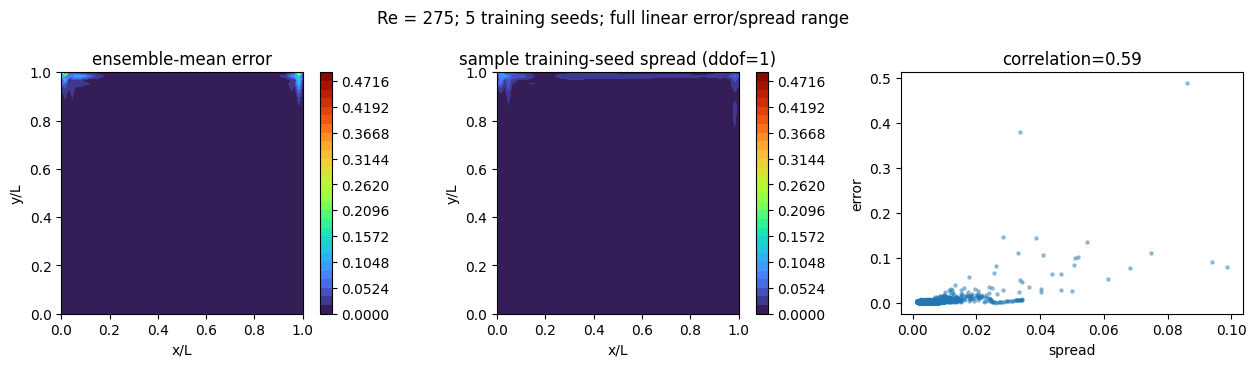

In [5]:
if VARIANT=="4A":
    r=275; stack_u=np.stack([seed_predictions[s][r][0] for s in SEEDS]);
    stack_v=np.stack([seed_predictions[s][r][1] for s in SEEDS]);
    stack_p=np.stack([seed_predictions[s][r][2] for s in SEEDS]);
    ensemble=(stack_u.mean(0),stack_v.mean(0),stack_p.mean(0))
    idx=int(np.where(data["Re"]==r)[0][0])
    spread=np.sqrt(stack_u.std(0, ddof=1)**2+stack_v.std(0, ddof=1)**2)
    error=np.hypot(ensemble[0]-data["u"][idx],ensemble[1]-data["v"][idx])
    corr=np.corrcoef(spread.ravel(),error.ravel())[0,1]
    print("correlation between ensemble spread and actual vector error:",corr)
    X,Y=np.meshgrid(data["x"],data["y"])
    fig,ax=plt.subplots(1,3,figsize=(13,3.7))
    limits=np.linspace(0,max(float(error.max()),float(spread.max()),1e-12),29)
    a=ax[0].contourf(X,Y,error,levels=limits,cmap="turbo");fig.colorbar(a,ax=ax[0]);ax[0].set_title("ensemble-mean error")
    a=ax[1].contourf(X,Y,spread,levels=limits,cmap="turbo");fig.colorbar(a,ax=ax[1]);ax[1].set_title("sample training-seed spread (ddof=1)")
    ax[2].scatter(spread.ravel(),error.ravel(),s=5,alpha=.4);ax[2].set(xlabel="spread",ylabel="error",title=f"correlation={corr:.2f}")
    for panel in ax[:2]:panel.set(xlabel="x/L",ylabel="y/L",aspect="equal")
    fig.suptitle(f"Re = {r}; {len(SEEDS)} training seeds; full linear error/spread range")
    plt.tight_layout();plt.show()
    seed_results.to_csv("P4_seed_results.csv",index=False)
else:
    size_results.to_csv("P4_data_size_results.csv",index=False)
    fig,ax=plt.subplots(1,2,figsize=(10,3.8))
    for label,g in size_results.groupby("case_set"):
        ax[0].plot(g["Re"],g["relative_L2_uv"],"o-",label=label)
        ax[1].plot(g["Re"],g["relative_L2_p"],"o-",label=label)
    for a in ax:a.grid(alpha=.3);a.legend(loc="upper left",bbox_to_anchor=(1.02,1));a.set_xlabel("public held-out Re")
    ax[0].set_ylabel("relative L2 velocity");ax[1].set_ylabel("relative L2 pressure")
    plt.tight_layout();plt.show()

### The ensemble must still reproduce a physical field

Sample spread across training seeds measures variability of this particular training procedure at fixed data, architecture and stopping rule. It is neither observation noise nor a calibrated posterior uncertainty. The ensemble can be confidently wrong if all members share representation or optimization bias. Compare the ensemble mean with CFD in velocity, pressure and streamlines before interpreting a spread/error correlation.

The profile band below is one **sample standard deviation** (ddof=1) across trained members, not a 95% prediction or confidence interval. It does not include source-CFD discretization error. Report member count and each seed; do not drop an unfavorable member after viewing the final case. Training time is recorded immediately after fitting and excludes later prediction and metric evaluation.


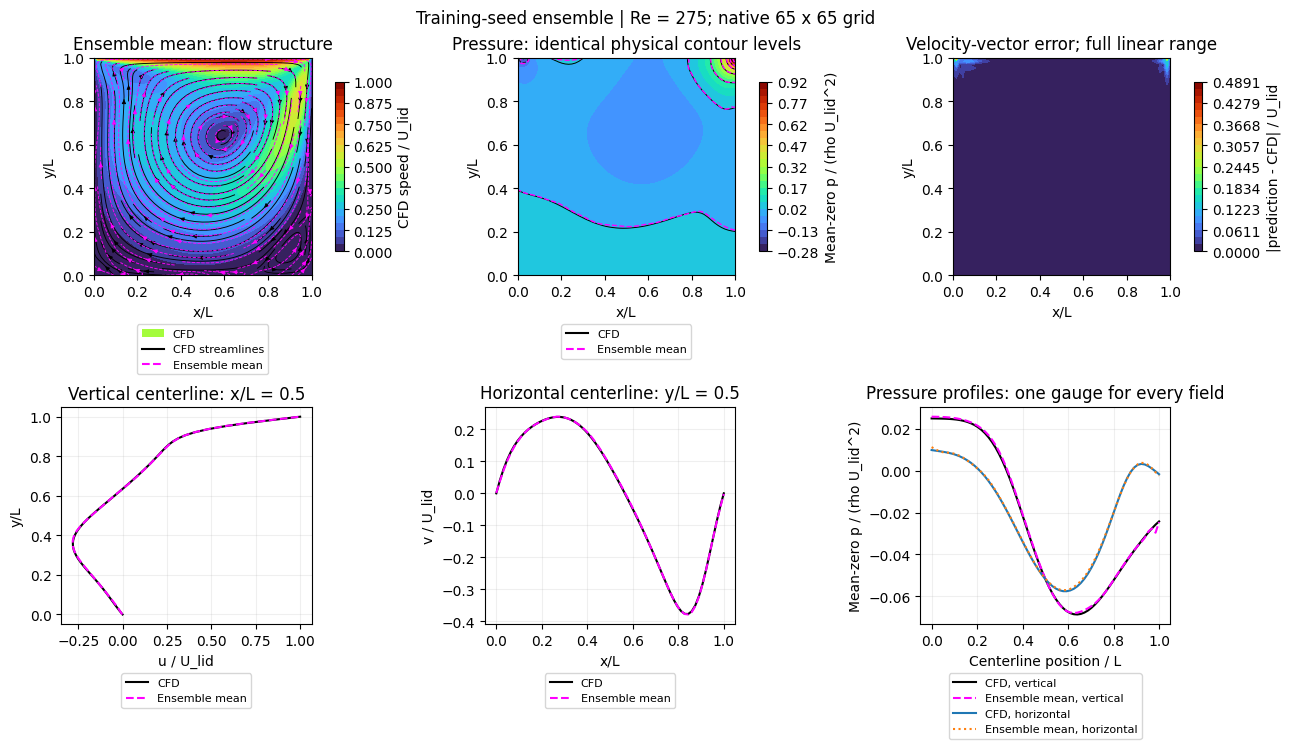

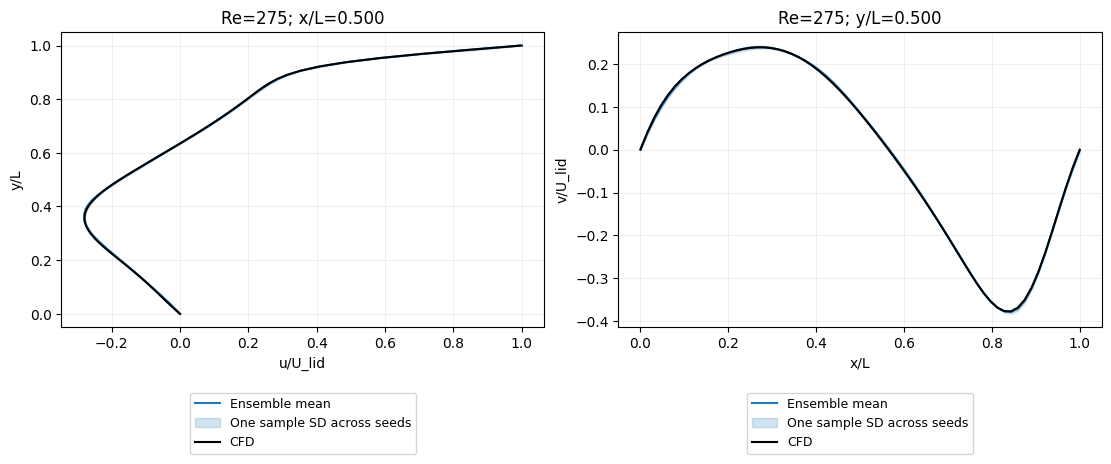

In [6]:
if VARIANT=="4A":
    physical=w5_common.plot_case_evidence(data,r,{"Ensemble mean":ensemble},"Training-seed ensemble")
    plt.show()
    x,y=data['x'],data['y'];ix=int(np.argmin(abs(x-.5)));iy=int(np.argmin(abs(y-.5)))
    fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
    mu=stack_u[:,:,ix].mean(axis=0);sd=stack_u[:,:,ix].std(axis=0,ddof=1)
    axes[0].plot(mu,y,color="tab:blue",label="Ensemble mean")
    axes[0].fill_betweenx(y,mu-sd,mu+sd,color="tab:blue",alpha=.2,label="One sample SD across seeds")
    axes[0].plot(data['u'][idx,:,ix],y,color="black",label="CFD")
    axes[0].set(xlabel="u/U_lid",ylabel="y/L",title=f"Re={r}; x/L={float(x[ix]):.3f}")
    mu=stack_v[:,iy,:].mean(axis=0);sd=stack_v[:,iy,:].std(axis=0,ddof=1)
    axes[1].plot(x,mu,color="tab:blue",label="Ensemble mean")
    axes[1].fill_between(x,mu-sd,mu+sd,color="tab:blue",alpha=.2,label="One sample SD across seeds")
    axes[1].plot(x,data['v'][idx,iy,:],color="black",label="CFD")
    axes[1].set(xlabel="x/L",ylabel="v/U_lid",title=f"Re={r}; y/L={float(y[iy]):.3f}")
    for a in axes:a.legend(loc="upper center",bbox_to_anchor=(.5,-.20),fontsize=9);a.grid(alpha=.2)
    plt.show()
else:
    physical=w5_common.plot_case_evidence(data,275,
        {label:predictions[275] for label,predictions in size_predictions.items()},
        "Training-case-count comparison")
    plt.show()


## Required report evidence

### Variant 4A
- Report mean, standard deviation, best, and worst error across seeds.
- Compare one model with the ensemble mean.
- Plot uncertainty/spread and actual error on the same blind case.
- Explain whether ensemble spread is a useful error indicator and where it fails.

### Variant 4B
- Keep network and training rules fixed.
- Report error versus both the number of development cases and the actual number of training cases, not merely the number of flattened grid points.
- Explain whether added cases improve interpolation, extrapolation, or both.
- Identify the smallest case set that preserves the central flow but loses a wall/corner feature.

For both variants, a result without repeated runs or a controlled data change is not an uncertainty study.

## Optional stretch extensions (advanced / prize-track only)

Complete the required project first. With instructor approval, choose at most one:

1. Evaluate whether ensemble spread is calibrated by plotting empirical error coverage at several spread thresholds.
2. Combine training-seed variability with development-case count in a small two-factor experiment.
3. Use ensemble disagreement as an acquisition score and test one simple active-learning choice against a random added Reynolds case.


## Concept check and further reading

1. What uncertainty source is measured by changing only neural initialization?
2. Why can five ensemble members agree and still be wrong?
3. Why should development sets be nested in a data-density study?
4. How would label uncertainty alter the interpretation of a seed ensemble?
5. Which additional experiment would separate numerical-label error from model error?

Read the reproducibility references in `references/README.md` and the uncertainty discussion in Karniadakis et al. (2021).


## Reproducibility record

Before closing the notebook, record:

- Python and package versions;
- dataset hash and helper versions;
- every physical case in development, validation, and blind sets;
- every seed and candidate value tried;
- the selection rule and when it was frozen;
- output filenames and units; and
- any cell that was skipped, changed, or run with a reduced budget.

Restart the kernel and run all cells in order. If the result changes materially, report the variability instead of selecting the preferred run.

## Troubleshooting without corrupting the experiment

| Symptom | Safe action | Unsafe action |
| --- | --- | --- |
| Missing helper/data file | Re-run the bootstrap and verify paths/hash | Download an unlabeled older copy |
| Training is slow | Use the documented smoke configuration, then label it “smoke” | Quietly reduce epochs/data in the final claim |
| Validation is poor | Inspect scaling, split, and baseline; revise on development data | Open the blind case to choose settings |
| Blind result fails | Report/localize failure and propose a new future experiment | Tune on the blind case while keeping its label “blind” |
| Stochastic result changes | Run multiple declared seeds and report mean/spread | Keep rerunning until one result looks good |
| A neural model loses to interpolation | Verify fairness, then recommend the simpler method | Hide the baseline |

## Final report outline

1. **Question and hypothesis** — one falsifiable sentence.
2. **Data and split** — physical cases, numerical source, and blind unit.
3. **Baseline** — simplest credible comparator using the same allowed information.
4. **Modification** — the one controlled change.
5. **Selection** — validation-only candidates and frozen rule.
6. **Blind numerical result** — aggregate errors and variability.
7. **Physical result** — at least two diagnostics tied to the flow.
8. **Failure or limitation** — where confidence ends.
9. **Cost and reproducibility** — runtime, environment, seeds, saved files.
10. **Conclusion** — helped, hurt, or revealed a tradeoff; no forced positive AI claim.


## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Foundational or supporting notebook; see ARTICLE_FIGURE_MAP.md for its evidence dependency.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).


<!-- FLOWMLLAB_EARLY_TEACHING_20261120 -->
